# Predict New York City Airbnb Prices - Linear Regression

**Student:** Chinmaya SD (USN 1AM25CI033) &nbsp;|&nbsp; **Course:** Unlox AIML - Minor Project 2

**Goal:** Build a Linear Regression model that predicts the nightly price of a New York City Airbnb listing,
and judge honestly how good it is.

**Dataset:** *New York City Airbnb Open Data* (AB_NYC_2019) - about 49,000 listings, originally published on Kaggle
by Dgomonov. The notebook reads the local file `AB_NYC_2019.csv` if it is present, otherwise it downloads the same
file from the public GitHub repository YueminLi/Airbnb_NYC_2019.

**Workflow (same order as the assignment):**
1. EDA and data auditing &rarr; 2. Cleaning and missing values &rarr; 3. Outliers &rarr; 4. Feature selection and encoding
&rarr; 5. Feature/target split and train-test split &rarr; 6. Model training and evaluation &rarr; 7. Residual analysis

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
os.makedirs("images", exist_ok=True)          # folder where key charts are saved

DATA_PATH = "AB_NYC_2019.csv"
DATA_URL = "https://raw.githubusercontent.com/YueminLi/Airbnb_NYC_2019/master/AB_NYC_2019.csv"
RANDOM_STATE = 42                              # reproducibility seed used everywhere

## Step 1: Exploratory Data Analysis (EDA) and Data Auditing

### Task 1.1 - Load the data and inspect shape, columns and data types

In [2]:
df = pd.read_csv(DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL)

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes)
df.head()

Shape (rows, columns): (48895, 16)

Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data types:
id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


### Task 1.2 - Numerical (discrete / continuous) and categorical (nominal / ordinal) columns

| Group | Columns | Why |
|---|---|---|
| Numerical - continuous | `latitude`, `longitude`, `price`, `reviews_per_month` | Can take any decimal value |
| Numerical - discrete | `minimum_nights`, `number_of_reviews`, `calculated_host_listings_count`, `availability_365` | Whole-number counts |
| Identifiers (numbers, but not real measurements) | `id`, `host_id` | Only labels; the number size means nothing |
| Categorical - nominal | `neighbourhood_group`, `neighbourhood`, `room_type` | Categories with no natural order |
| Categorical - ordinal | none | No column has a ranked order in this dataset |
| Text | `name`, `host_name` | Free text / names |
| Date (stored as text) | `last_review` | Date string |

In [3]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = [c for c in df.columns if c not in numeric_cols]
print("Numeric columns :", numeric_cols)
print("Text/categorical:", text_cols)
print("\nUnique values in the categorical columns:")
for c in ["neighbourhood_group", "neighbourhood", "room_type"]:
    print(f"  {c}: {df[c].nunique()} unique")
print("\nneighbourhood_group values:", df["neighbourhood_group"].unique().tolist())
print("room_type values          :", df["room_type"].unique().tolist())

Numeric columns : ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Text/categorical: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']

Unique values in the categorical columns:
  neighbourhood_group: 5 unique
  neighbourhood: 221 unique
  room_type: 3 unique

neighbourhood_group values: ['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
room_type values          : ['Private room', 'Entire home/apt', 'Shared room']


### Task 1.3 - Missing values in every column (count and percentage)

In [4]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().sum() / len(df) * 100).round(2),
})
missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_percent
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


**What the audit shows:** four columns have missing data - `last_review` and `reviews_per_month` (about 20.6% each, the
same rows), plus a handful of missing `name` and `host_name` values (under 0.05%). All other columns are complete.

## Step 2: Data Cleaning and Handling Missing Values

### Task 2.1 - The `last_review` column: drop or engineer?
First I check *why* it is missing.

In [5]:
never_reviewed = df["number_of_reviews"] == 0
print("Listings with zero reviews              :", never_reviewed.sum())
print("Listings with missing last_review       :", df["last_review"].isna().sum())
print("Missing last_review only when 0 reviews :",
      (df.loc[df["last_review"].isna(), "number_of_reviews"] == 0).all())

Listings with zero reviews              : 10052
Listings with missing last_review       : 10052
Missing last_review only when 0 reviews : True


**Decision: drop `last_review`.** I considered engineering it (for example 'days since last review') but rejected that for three reasons. (1) It is a date stored as text, so it cannot go into a linear equation as it is. (2) All 10,052 missing values (20.6% of the data) are listings that have never been reviewed, so there is no date to recover; any fill value would be invented for one fifth of the rows. (3) The review activity it describes is already captured by `number_of_reviews` and `reviews_per_month`, which I keep. Dropping it loses almost no useful information and keeps the model simple.

In [6]:
df = df.drop(columns=["last_review"])
print("last_review dropped. Columns left:", df.shape[1])

last_review dropped. Columns left: 15


### Task 2.2 - The `reviews_per_month` column
The hint is to look at the number of reviews for the rows where it is missing.

In [7]:
missing_rpm = df[df["reviews_per_month"].isna()]
print("Rows with missing reviews_per_month:", len(missing_rpm))
print("Of those, rows with number_of_reviews == 0:", (missing_rpm["number_of_reviews"] == 0).sum())
print("Summary of number_of_reviews in those rows:")
print(missing_rpm["number_of_reviews"].describe())

Rows with missing reviews_per_month: 10052
Of those, rows with number_of_reviews == 0: 10052
Summary of number_of_reviews in those rows:
count    10052.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: number_of_reviews, dtype: float64


**Finding:** every row with a missing `reviews_per_month` has `number_of_reviews == 0`. The value is missing because a
listing with no reviews has no review rate to calculate - not because data was lost. The logical replacement is **0**
(zero reviews per month), not the mean or median, which would wrongly invent review activity.

In [8]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
print("Missing reviews_per_month after filling:", df["reviews_per_month"].isna().sum())

Missing reviews_per_month after filling: 0


### Task 2.3 - Drop identifier columns
`id` and `host_id` are unique labels and `name` / `host_name` are free text. A mathematical model cannot learn a price
rule from them (and `host_name` / `name` hold the last few missing values), so they are removed.

In [9]:
df = df.drop(columns=["id", "name", "host_id", "host_name"])
print("Remaining columns:", list(df.columns))
print("Missing values left in whole dataset:", int(df.isna().sum().sum()))

Remaining columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Missing values left in whole dataset: 0


## Step 3: Outlier Identification and Treatment
Linear Regression is very sensitive to extreme values, because it minimises squared errors and one huge price can pull
the whole line towards it.

### Task 3.1 - Boxplots and histograms for `price` and `minimum_nights`

In [10]:
print("price summary:")
print(df["price"].describe().round(1))
print("\nListings priced at $0        :", (df["price"] == 0).sum())
print("Listings priced $1,000 or more:", (df["price"] >= 1000).sum())
print("Listings priced $10,000       :", (df["price"] >= 10000).sum())
print("\nminimum_nights summary:")
print(df["minimum_nights"].describe().round(1))
print("Listings with minimum_nights >= 365:", (df["minimum_nights"] >= 365).sum())
print("Listings with minimum_nights > 30  :", (df["minimum_nights"] > 30).sum())

price summary:
count    48895.0
mean       152.7
std        240.2
min          0.0
25%         69.0
50%        106.0
75%        175.0
max      10000.0
Name: price, dtype: float64

Listings priced at $0        : 11
Listings priced $1,000 or more: 298
Listings priced $10,000       : 3

minimum_nights summary:
count    48895.0
mean         7.0
std         20.5
min          1.0
25%          1.0
50%          3.0
75%          5.0
max       1250.0
Name: minimum_nights, dtype: float64
Listings with minimum_nights >= 365: 43
Listings with minimum_nights > 30  : 747


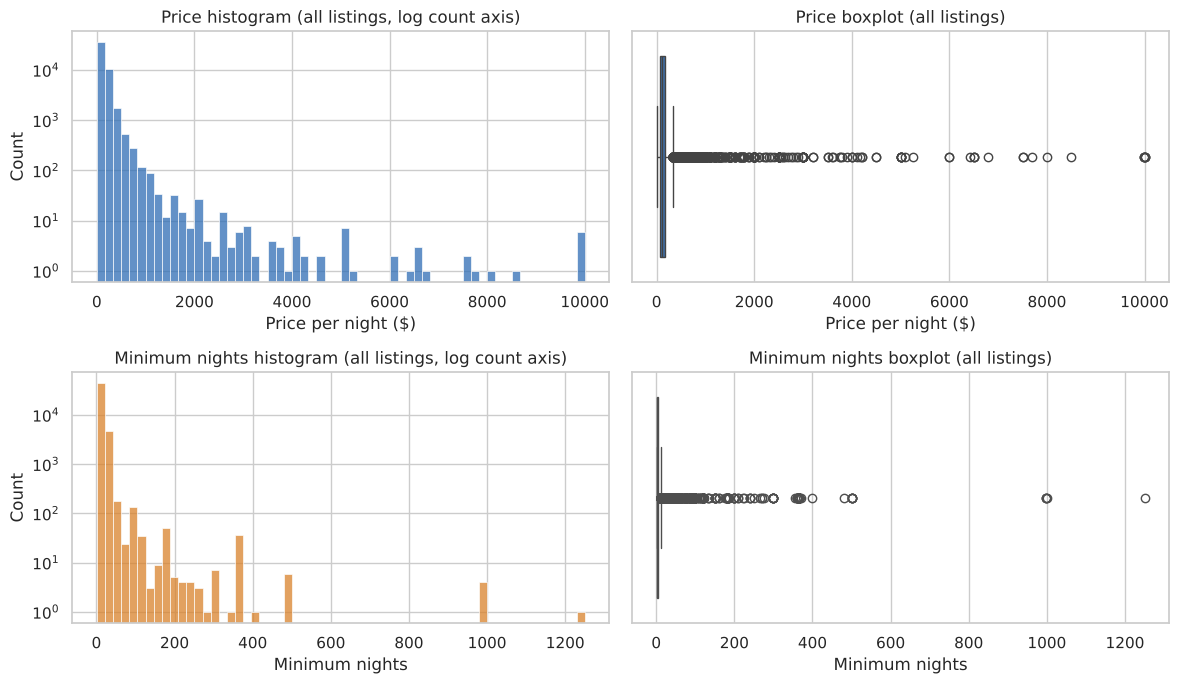

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

sns.histplot(df["price"], bins=60, ax=axes[0, 0], color="#2f6db5")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Price histogram (all listings, log count axis)")
axes[0, 0].set_xlabel("Price per night ($)")

sns.boxplot(x=df["price"], ax=axes[0, 1], color="#2f6db5")
axes[0, 1].set_title("Price boxplot (all listings)")
axes[0, 1].set_xlabel("Price per night ($)")

sns.histplot(df["minimum_nights"], bins=60, ax=axes[1, 0], color="#d9822b")
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Minimum nights histogram (all listings, log count axis)")
axes[1, 0].set_xlabel("Minimum nights")

sns.boxplot(x=df["minimum_nights"], ax=axes[1, 1], color="#d9822b")
axes[1, 1].set_title("Minimum nights boxplot (all listings)")
axes[1, 1].set_xlabel("Minimum nights")

plt.tight_layout()
plt.savefig("images/01_outliers_before.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** Both columns are extremely right-skewed. **Price:** the median is \$106 but the maximum is \$10,000; 298 listings cost \$1,000 or more, 3 cost \$10,000 a night, and 11 listings have a price of \$0, which is not a real price. **Minimum nights:** the median is 3 nights but the maximum is 1,250; 43 listings require 365+ nights (long-term leases, not nightly rentals) and 747 require more than 30 nights. The boxplots show a few points stretched far to the right. If kept, these would pull the regression line towards them.

### Task 3.2 - Trimming strategy (95th percentile rule)
1. **Remove `price == 0` rows first.** A free listing is not a real price; it is a data error and would be wrong as a target.
2. **Trim `price` and `minimum_nights` above their 95th percentiles.** This removes the extreme luxury listings and the
   long-term rentals (a 365-night minimum is a lease, not a vacation stay), so the model learns the *typical consumer market*.

In [12]:
rows_before = len(df)

# 1) invalid zero prices
zero_price = (df["price"] == 0).sum()
df = df[df["price"] > 0]

# 2) 95th percentile caps
price_cap = df["price"].quantile(0.95)
nights_cap = df["minimum_nights"].quantile(0.95)
print(f"95th percentile of price          : ${price_cap:,.0f}")
print(f"95th percentile of minimum_nights : {nights_cap:,.0f} nights")

df = df[(df["price"] <= price_cap) & (df["minimum_nights"] <= nights_cap)].reset_index(drop=True)

rows_after = len(df)
print(f"\nZero-price rows removed : {zero_price}")
print(f"Rows before trimming    : {rows_before:,}")
print(f"Rows after trimming     : {rows_after:,}")
print(f"Total removed           : {rows_before - rows_after:,} ({(rows_before - rows_after) / rows_before:.1%})")
print("\nprice after trimming:")
print(df["price"].describe().round(1))

95th percentile of price          : $355
95th percentile of minimum_nights : 30 nights

Zero-price rows removed : 11
Rows before trimming    : 48,895
Rows after trimming     : 45,748
Total removed           : 3,147 (6.4%)

price after trimming:
count    45748.0
mean       122.5
std         72.0
min         10.0
25%         65.0
50%        100.0
75%        160.0
max        355.0
Name: price, dtype: float64


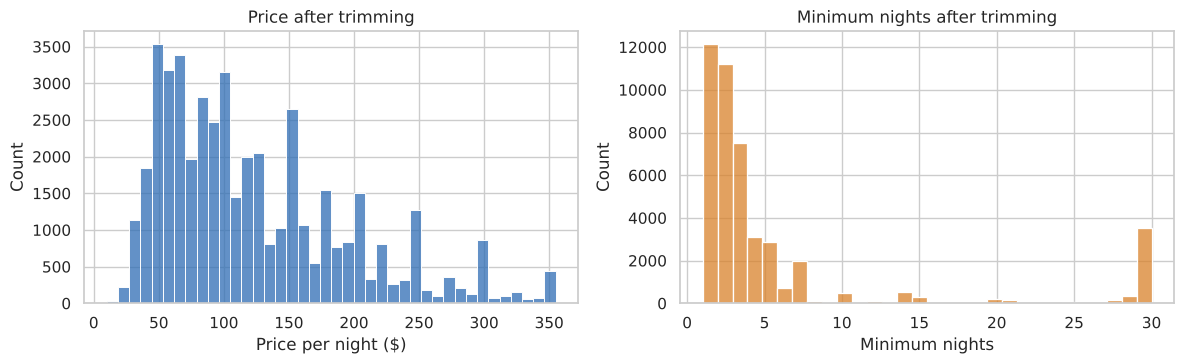

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["price"], bins=40, ax=axes[0], color="#2f6db5")
axes[0].set_title("Price after trimming")
axes[0].set_xlabel("Price per night ($)")
sns.histplot(df["minimum_nights"], bins=30, ax=axes[1], color="#d9822b")
axes[1].set_title("Minimum nights after trimming")
axes[1].set_xlabel("Minimum nights")
plt.tight_layout()
plt.savefig("images/02_outliers_after.png", dpi=150, bbox_inches="tight")
plt.show()

**Result:** The trimming removed 3,147 rows (6.4%): 11 zero-price listings plus every listing above the 95th percentiles (\$355 per night and 30 minimum nights). Price now runs from \$10 to \$355 with a mean of \$122.5 and a median of \$100, and minimum stays are at most 30 nights. All three \$10,000 listings and all 43 listings with a 365+ night minimum are gone, so the model now focuses on the typical consumer market.

## Step 4: Feature Selection and Categorical Encoding

### Task 4.1 - High cardinality: `neighbourhood` (200+ values) vs `neighbourhood_group` (5 values)

In [14]:
n_hood = df["neighbourhood"].nunique()
n_group = df["neighbourhood_group"].nunique()
print("Unique neighbourhood values       :", n_hood)
print("Unique neighbourhood_group values :", n_group)
print(f"One-hot columns needed (drop_first): neighbourhood = {n_hood - 1}, neighbourhood_group = {n_group - 1}")
print("\nListings per neighbourhood (smallest 5):")
print(df["neighbourhood"].value_counts().tail(5))

Unique neighbourhood values       : 219
Unique neighbourhood_group values : 5
One-hot columns needed (drop_first): neighbourhood = 218, neighbourhood_group = 4

Listings per neighbourhood (smallest 5):
neighbourhood
Bay Terrace, Staten Island    2
Richmondtown                  1
New Dorp                      1
Rossville                     1
Willowbrook                   1
Name: count, dtype: int64


**Why the 200+ value column breaks the model's simplicity (the Curse of Dimensionality):**
The neighbourhood column has 219 unique values here (221 in the raw data), which would need 218 extra dummy columns after One-Hot Encoding, compared with just 4 for the five boroughs. That hurts the model in four ways: (1) the data becomes very sparse, with almost every dummy column being 0; (2) many neighbourhoods have tiny samples (some have only 1 or 2 listings, such as Richmondtown and New Dorp), so their coefficients would be learned from one listing and would be noise, which invites overfitting; (3) with that many columns the model needs far more data to estimate reliable coefficients and becomes harder to interpret; (4) it adds nothing much, because `latitude`, `longitude` and the borough already describe location. This is the Curse of Dimensionality: more columns spread the same rows thinner, so the model gets more complex but not more accurate.

**Decision:** drop `neighbourhood` and keep `neighbourhood_group` (5 boroughs).

In [15]:
df = df.drop(columns=["neighbourhood"])
print("Columns now:", list(df.columns))

Columns now: ['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


### Task 4.2 - One-Hot Encoding for `neighbourhood_group` and `room_type`
`drop_first=True` removes one dummy column per feature so the remaining dummies are not perfectly predictable from each
other (the **Dummy Variable Trap**). The dropped category becomes the baseline the model compares against.

In [16]:
df_encoded = pd.get_dummies(df, columns=["neighbourhood_group", "room_type"], drop_first=True, dtype=int)
print("Shape after encoding:", df_encoded.shape)
print("Columns:", list(df_encoded.columns))
df_encoded.head()

Shape after encoding: (45748, 14)
Columns: ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


Baselines (dropped categories): **Bronx** for `neighbourhood_group` and **Entire home/apt** for `room_type`
(they come first alphabetically). Every dummy coefficient later is read as "compared with that baseline".

## Step 5: Feature-Target Separation and Validation Split

### Task 5.1 - Features (X) and target (y)

In [17]:
X = df_encoded.drop(columns=["price"])      # everything except the price
y = df_encoded["price"]                     # what we want to predict
print("X shape:", X.shape, "| y shape:", y.shape)
print("Feature columns:", list(X.columns))

X shape: (45748, 13) | y shape: (45748,)
Feature columns: ['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


### Task 5.2 - 80% training / 20% testing split with a fixed seed

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0] / len(X):.0%})")
print(f"Testing set : {X_test.shape[0]:,} rows ({X_test.shape[0] / len(X):.0%})")
print("random_state =", RANDOM_STATE)

Training set: 36,598 rows (80%)
Testing set : 9,150 rows (20%)
random_state = 42


## Step 6: Model Training and Evaluation

### Task 6.1 - Fit a standard Linear Regression model

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept: $%.2f" % model.intercept_)
coef_table = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_})
coef_table = coef_table.reindex(coef_table["coefficient"].abs().sort_values(ascending=False).index)
coef_table.round(3).reset_index(drop=True)

Intercept: $-18740.60


,feature,coefficient
0,longitude,-297.507
1,room_type_Shared room,-104.577
2,neighbourhood_group_Staten Island,-82.934
3,room_type_Private room,-79.117
4,latitude,-76.227
5,neighbourhood_group_Manhattan,23.448
6,neighbourhood_group_Brooklyn,-8.211
7,neighbourhood_group_Queens,5.668
8,reviews_per_month,-1.060
9,minimum_nights,-1.038


### Task 6.2 - Predict prices for the hidden test data

In [20]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({"Actual price": y_test.values, "Predicted price": y_pred.round(2)}).head(8)
comparison

,Actual price,Predicted price
0,80,107.11
1,73,145.83
2,186,184.77
3,150,166.01
4,229,140.96
5,180,157.90
6,180,145.20
7,49,72.33


### Task 6.3 - Evaluation metrics
- **R-squared (R2):** share of the price variation the model explains (1.0 = perfect, 0 = no better than guessing the average).
- **MAE:** average mistake in dollars.
- **MSE / RMSE:** squares the mistakes first, so big misses are punished more. RMSE brings it back to dollars.

In [21]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2_train = r2_score(y_train, model.predict(X_train))

print(f"R-squared (test)  : {r2:.4f}  -> explains {r2:.1%} of the price variation")
print(f"R-squared (train) : {r2_train:.4f}")
print(f"MAE               : ${mae:.2f}")
print(f"MSE               : {mse:,.2f}")
print(f"RMSE              : ${rmse:.2f}")
print(f"\nAverage actual price in the test set: ${y_test.mean():.2f}")
print(f"MAE as a share of the average price : {mae / y_test.mean():.1%}")
print(f"RMSE / MAE ratio: {rmse / mae:.2f}  (above 1 means some large misses)")

R-squared (test)  : 0.4868  -> explains 48.7% of the price variation
R-squared (train) : 0.4749
MAE               : $38.32
MSE               : 2,760.62
RMSE              : $52.54

Average actual price in the test set: $123.67
MAE as a share of the average price : 31.0%
RMSE / MAE ratio: 1.37  (above 1 means some large misses)


**Reading the numbers:** The model explains about **49% of the variation in prices** on listings it has never seen (R-squared = 0.49). The training R-squared is almost the same (0.47), so the model is not overfitting; it is limited by the information available, because the data has no apartment size, quality, amenities or photos. The **MAE is about \$38**, meaning a typical prediction is off by \$38 per night, which is roughly 31% of the average price (\$124). The **RMSE (\$53) is higher than the MAE**, which tells us that some predictions are wrong by a lot, and the analysis below shows these are mostly the expensive listings.

## Step 7: Residual Analysis and Interpretation

### Task 7.1 - Actual vs Predicted prices (with the perfect-prediction line)

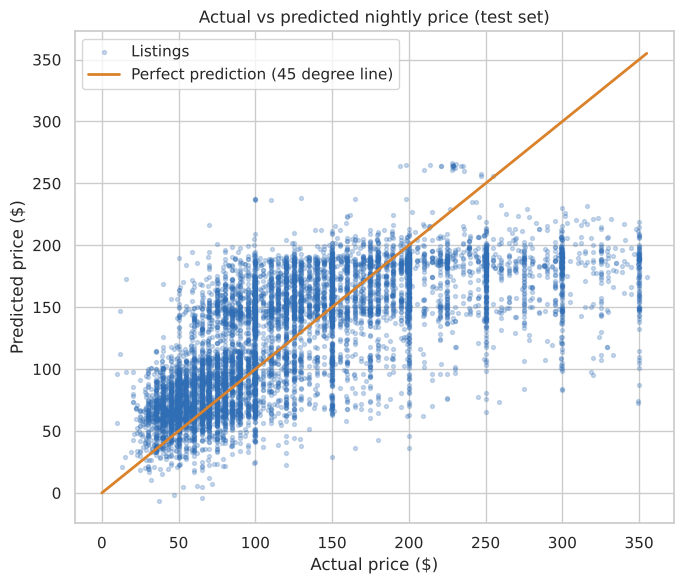

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, s=8, alpha=0.25, color="#2f6db5", label="Listings")
lims = [0, max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, color="#d9822b", linewidth=2, label="Perfect prediction (45 degree line)")
ax.set_xlabel("Actual price ($)")
ax.set_ylabel("Predicted price ($)")
ax.set_title("Actual vs predicted nightly price (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("images/03_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** If the model were perfect, every dot would sit on the orange line. For cheap and mid-priced listings (about \$30 to \$150) the dots cluster loosely around the line. For higher actual prices the dots flatten out: listings that really cost \$250 to \$355 are mostly predicted at only about \$100 to \$225, and the model almost never predicts above roughly \$265. In other words, the model pulls predictions towards the middle and cannot reach the top of the price range. The vertical stripes appear because hosts like round prices (\$100, \$150, \$200, \$250 and so on).

### Task 7.2 - Residual plot and error distribution

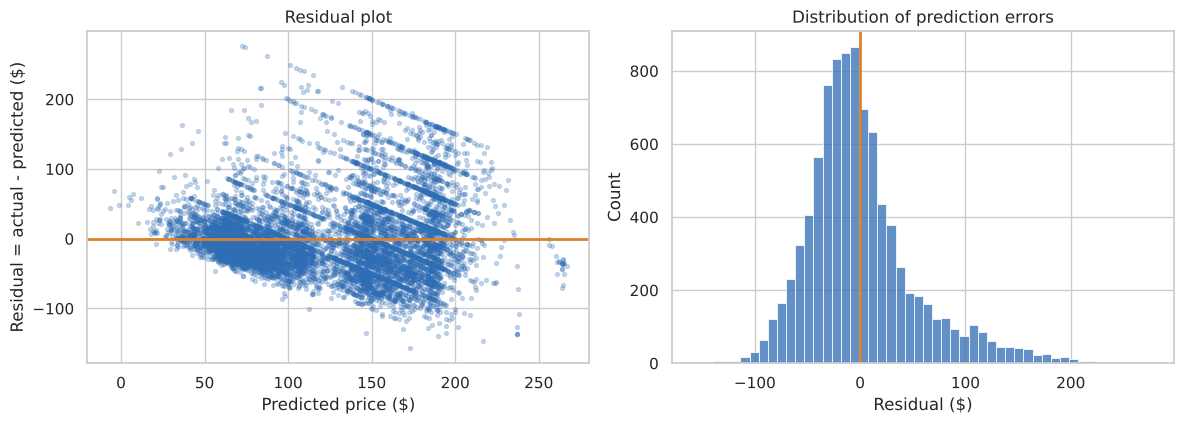

Mean residual   : $0.98 (near 0 means no overall bias)
Residual std dev: $52.53


In [23]:
residuals = y_test.values - y_pred          # actual minus predicted (positive = model guessed too low)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].scatter(y_pred, residuals, s=8, alpha=0.25, color="#2f6db5")
axes[0].axhline(0, color="#d9822b", linewidth=2)
axes[0].set_xlabel("Predicted price ($)")
axes[0].set_ylabel("Residual = actual - predicted ($)")
axes[0].set_title("Residual plot")

sns.histplot(residuals, bins=50, ax=axes[1], color="#2f6db5")
axes[1].axvline(0, color="#d9822b", linewidth=2)
axes[1].set_xlabel("Residual ($)")
axes[1].set_title("Distribution of prediction errors")
plt.tight_layout()
plt.savefig("images/04_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean residual   : ${residuals.mean():.2f} (near 0 means no overall bias)")
print(f"Residual std dev: ${residuals.std():.2f}")

**Observation:** The error histogram is centred near zero (mean residual about \$1), so the model is not biased overall, but it has a **long right tail**: some listings are \$150 to \$270 more expensive than predicted, while very few are that much cheaper. The residual plot is not a random cloud: the spread of errors is wider for higher predictions, and the diagonal streaks come from the round-number prices (when the actual price is fixed, the residual falls in a straight line as the prediction rises). A pattern in the residuals means a straight-line model is missing something, here mainly the features that make a listing expensive.

### Task 7.3 - Does the model perform better on cheap or expensive listings, and why?
I split the test listings into price bands and compare the errors in each band.

In [24]:
bands = pd.cut(y_test, bins=[0, 75, 150, 250, 355],
               labels=["Budget (up to $75)", "Mid ($76-150)", "Upper ($151-250)", "Premium ($251-355)"])
by_band = pd.DataFrame({"band": bands.values, "actual": y_test.values,
                        "predicted": y_pred, "residual": residuals})
band_report = by_band.groupby("band", observed=True).agg(
    listings=("actual", "size"),
    avg_actual_price=("actual", "mean"),
    avg_predicted_price=("predicted", "mean"),
    MAE=("residual", lambda r: r.abs().mean()),
    mean_residual=("residual", "mean"),
)
band_report["MAE_as_%_of_price"] = band_report["MAE"] / band_report["avg_actual_price"] * 100
band_report.round(1)

,listings,avg_actual_price,avg_predicted_price,MAE,mean_residual,MAE_as_%_of_price
band,,,,,,
Budget (up to $75),2990,55.1,77.2,26.2,-22.1,47.5
Mid ($76-150),3665,111.4,128.7,32.8,-17.2,29.4
Upper ($151-250),1884,198.2,166.4,39.3,31.8,19.8
Premium ($251-355),611,302.6,174.9,127.8,127.8,42.2


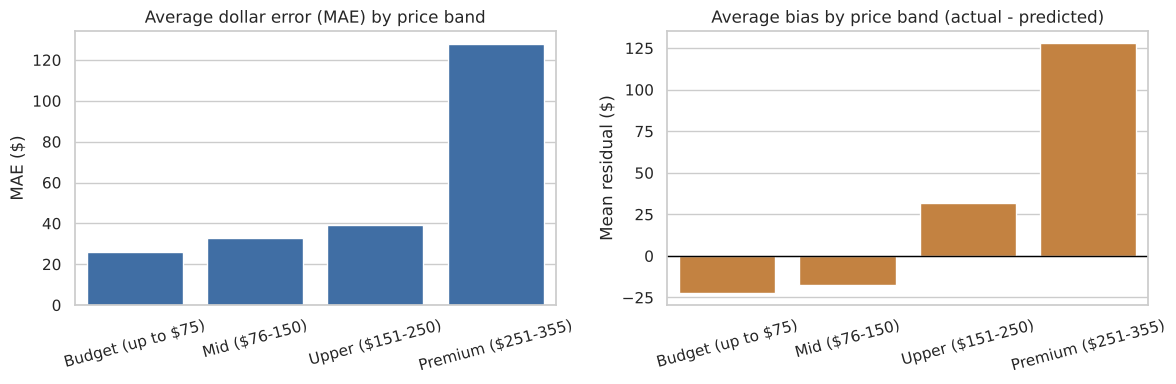

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=band_report.index.astype(str), y=band_report["MAE"], color="#2f6db5", ax=axes[0])
axes[0].set_title("Average dollar error (MAE) by price band")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE ($)")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(x=band_report.index.astype(str), y=band_report["mean_residual"], color="#d9822b", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Average bias by price band (actual - predicted)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean residual ($)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("images/05_error_by_price_band.png", dpi=150, bbox_inches="tight")
plt.show()

**Answer to the final project question:** **It is more accurate on cheap and mid-priced listings in dollar terms, and clearly worst on expensive listings.** The average dollar error rises from about \$26 for budget listings (up to \$75) to \$33 (mid), \$39 (upper) and **\$128 for premium listings (\$251 to \$355)**. For premium listings the model predicts about \$175 on average when the real average is \$303, so it under-prices them by about \$128. The bias also flips direction: the model **over-predicts** budget listings (by about \$22) and mid listings (by about \$17) and **under-predicts** upper and premium listings (by about \$32 and \$128). In percentage terms the best band is \$151 to \$250 (error about 20% of the price), while budget listings have a high relative error (about 48%) because a \$26 miss matters a lot on a \$55 room.

**Why this happens:** (1) A straight-line model with a few features predicts a smooth, middle-of-the-road price and pulls every prediction towards the average (regression towards the mean), so it cannot reach the extremes. (2) What makes a listing expensive (size, luxury finishes, exact street, view, amenities) is not in the data; the model only knows borough, room type, a rough map position and review counts, so a premium apartment and an ordinary one in the same area look the same to it. (3) Prices are skewed, so there are many cheap listings and few expensive ones; the line is fitted mainly to the crowded low-price area. (4) Because errors are squared, the few large misses on expensive listings also drive the higher RMSE.

## Final Summary (plain English for a business stakeholder)

In [26]:
print(f"Final R-squared : {r2:.2f}   |   Final MAE : ${mae:.0f}   |   RMSE : ${rmse:.0f}")
print(f"Listings used   : {len(df_encoded):,} (train {len(X_train):,} / test {len(X_test):,})")

Final R-squared : 0.49   |   Final MAE : $38   |   RMSE : $53
Listings used   : 45,748 (train 36,598 / test 9,150)


**In plain English:** the model gets a listing's nightly price right to within about **\$38 on average** (MAE), against an average price of about \$124. It explains about **49% of why prices differ** from listing to listing (R-squared = 0.49); the rest depends on things the dataset does not record, like size, quality and amenities. The model is **a reasonable guide for typical listings priced up to about \$250 a night, but it should not be trusted for premium listings**, where it under-prices by over \$100 on average. The main price drivers it found are location (longitude and borough, with Manhattan the most expensive) and room type (a private room is about \$79 cheaper and a shared room about \$105 cheaper than a whole apartment, other things equal).

**Limits:** only listings priced up to \$355 with stays of up to 30 nights were modelled, and the data is from 2019. **Next steps:** add features such as apartment size, number of bedrooms and amenities, or try models that can capture non-linear patterns, such as random forests.